In [ ]:
# 1. Mount your Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Define your paths (Change 'my_dataset.zip' to your actual file name)
drive_zip_path = '/content/drive/MyDrive/dataset/archive.zip'
local_zip_path = '/content/my_dataset.zip'
extract_to_path = '/content/dataset/'

print("🚀 Starting fast-copy from Google Drive to local SSD...")

# 3. Copy the zip file locally using 'cp' (takes only a few seconds for 2.4 GB)
!cp "{drive_zip_path}" "{local_zip_path}"

print("📦 Unzipping files locally...")

# 4. Unzip quietly (-q suppresses millions of print lines, saving browser memory)
!unzip -q "{local_zip_path}" -d "{extract_to_path}"

# 5. Clean up the local zip to free up space
!rm "{local_zip_path}"

print("✅ Done! Your data is ready at:", extract_to_path)


Mounted at /content/drive
🚀 Starting fast-copy from Google Drive to local SSD...
📦 Unzipping files locally...
✅ Done! Your data is ready at: /content/dataset/


In [ ]:
import os
import random
import shutil
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve,
    auc
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

# Mixed precision can reduce GPU memory use on compatible GPUs.
if tf.config.list_physical_devices("GPU"):
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
else:
    tf.keras.mixed_precision.set_global_policy("float32")

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

import os
from pathlib import Path

# Dataset is already available on Colab local storage
DATA_DIR = "/content/dataset/"

# Verify dataset directory
if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        f"Dataset directory not found: {DATA_DIR}"
    )

# Locate the PlantVillage color folder automatically
if os.path.isdir(os.path.join(DATA_DIR, "color")):
    DATA_DIR = os.path.join(DATA_DIR, "color")
else:
    matches = list(Path(DATA_DIR).rglob("color"))

    if matches:
        DATA_DIR = str(matches[0])

# Identify class folders
class_folders = sorted([
    folder.name
    for folder in Path(DATA_DIR).iterdir()
    if folder.is_dir()
])

if len(class_folders) < 2:
    raise ValueError(
        f"Expected disease class folders inside {DATA_DIR}. "
        "Check your dataset directory structure."
    )

print("Dataset path:", DATA_DIR)
print("Number of classes:", len(class_folders))
print("\nClass folders:")

for folder in class_folders:
    image_count = sum(
        1 for file in (Path(DATA_DIR) / folder).rglob("*")
        if file.is_file()
        and file.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }
    )
    print(f"{folder}: {image_count} images")


Dataset path: /content/dataset/plantvillage dataset/color
Number of classes: 38

Class folders:
Apple___Apple_scab: 630 images
Apple___Black_rot: 621 images
Apple___Cedar_apple_rust: 275 images
Apple___healthy: 1645 images
Blueberry___healthy: 1502 images
Cherry_(including_sour)___Powdery_mildew: 1052 images
Cherry_(including_sour)___healthy: 854 images
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513 images
Corn_(maize)___Common_rust_: 1192 images
Corn_(maize)___Northern_Leaf_Blight: 985 images
Corn_(maize)___healthy: 1162 images
Grape___Black_rot: 1180 images
Grape___Esca_(Black_Measles): 1383 images
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076 images
Grape___healthy: 423 images
Orange___Haunglongbing_(Citrus_greening): 5507 images
Peach___Bacterial_spot: 2297 images
Peach___healthy: 360 images
Pepper,_bell___Bacterial_spot: 997 images
Pepper,_bell___healthy: 1478 images
Potato___Early_blight: 1000 images
Potato___Late_blight: 1000 images
Potato___healthy: 152 images
Raspb

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
NUM_CLASSES_EXPECTED = None  # Set to 38 if your dataset has 38 classes.

PATCH_SIZE = 16
EMBED_DIM = 128
NUM_HEADS = 4
MLP_DIM = 256
NUM_TRANSFORMER_BLOCKS = 4
DROPOUT = 0.15

LEARNING_RATE = 1e-4

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)

Image size: 224
Batch size: 32
Maximum epochs: 50


In [ ]:
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_names = sorted([
    p.name for p in Path(DATA_DIR).iterdir() if p.is_dir()
])

if len(class_names) < 2:
    raise ValueError("Expected at least two class directories.")

if NUM_CLASSES_EXPECTED is not None:
    assert len(class_names) == NUM_CLASSES_EXPECTED, (
        f"Expected {NUM_CLASSES_EXPECTED} classes, "
        f"found {len(class_names)}."
    )

class_to_id = {name: i for i, name in enumerate(class_names)}

file_paths, labels = [], []

for class_name in class_names:
    folder = Path(DATA_DIR) / class_name

    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS:
            file_paths.append(str(path))
            labels.append(class_to_id[class_name])

file_paths = np.array(file_paths)
labels = np.array(labels, dtype=np.int32)

print("Total images:", len(file_paths))
print("Number of classes:", len(class_names))
print("Classes:", class_names)

print("\nImages per class:")
for name, class_id in class_to_id.items():
    print(f"{name}: {np.sum(labels == class_id)}")

Total images: 54305
Number of classes: 38
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print(f"Train: {len(X_train)} images")
print(f"Validation: {len(X_val)} images")
print(f"Test: {len(X_test)} images")

assert set(X_train).isdisjoint(set(X_val))
assert set(X_train).isdisjoint(set(X_test))
assert set(X_val).isdisjoint(set(X_test))

Train: 38013 images
Validation: 8146 images
Test: 8146 images


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image, [IMG_SIZE, IMG_SIZE],
        method="bilinear"
    )

    image = tf.cast(image, tf.float32) / 255.0
    label = tf.cast(label, tf.int32)

    return image, label


def make_dataset(paths, targets, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, targets))

    if training:
        ds = ds.shuffle(
            min(len(paths), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    # Cache only if the resized dataset comfortably fits in RAM.
    # Disk cache can be used instead for larger datasets.
    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(AUTOTUNE)
    return ds


train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

for images, batch_labels in train_ds.take(1):
    print("RGB batch:", images.shape)
    print("Labels batch:", batch_labels.shape)
    print("RGB range:", float(tf.reduce_min(images)),
          float(tf.reduce_max(images)))

RGB batch: (32, 224, 224, 3)
Labels batch: (32,)
RGB range: 0.0 1.0


In [ ]:
@tf.keras.utils.register_keras_serializable(package="FAViT")
class DFTMagnitude(tf.keras.layers.Layer):
    """Compute normalized log-magnitude 2D DFT from RGB images."""

    def call(self, inputs):
        # Input: (batch, height, width, 3), values in [0, 1]
        gray = tf.image.rgb_to_grayscale(inputs)
        gray = tf.squeeze(gray, axis=-1)

        # Float image -> complex image -> 2D FFT
        complex_image = tf.cast(gray, tf.complex64)
        spectrum = tf.signal.fft2d(complex_image)

        # Move zero frequency to the center.
        spectrum = tf.signal.fftshift(spectrum, axes=(-2, -1))

        # Log magnitude compresses the dynamic range.
        magnitude = tf.math.log1p(tf.abs(spectrum))

        # Per-image normalization.
        mean = tf.reduce_mean(
            magnitude, axis=(1, 2), keepdims=True
        )
        variance = tf.reduce_mean(
            tf.square(magnitude - mean),
            axis=(1, 2),
            keepdims=True
        )

        normalized = (
            magnitude - mean
        ) / tf.sqrt(variance + 1e-6)

        return tf.expand_dims(normalized, axis=-1)

    def compute_output_shape(self, input_shape):
        return (
            input_shape[0],
            input_shape[1],
            input_shape[2],
            1
        )

In [ ]:
@tf.keras.utils.register_keras_serializable(package="FAViT")
class PatchEmbedding(tf.keras.layers.Layer):
    def __init__(
        self,
        embed_dim=128,
        patch_size=16,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.patch_size = patch_size

        self.projection = tf.keras.layers.Conv2D(
            filters=embed_dim,
            kernel_size=patch_size,
            strides=patch_size,
            padding="valid"
        )

        self.num_patches = (IMG_SIZE // patch_size) ** 2
        self.position_embedding = tf.keras.layers.Embedding(
            input_dim=self.num_patches,
            output_dim=embed_dim
        )

    def call(self, inputs):
        x = self.projection(inputs)

        # Convert spatial feature map into patch tokens.
        x = tf.reshape(
            x,
            [tf.shape(x)[0], self.num_patches, self.embed_dim]
        )

        positions = tf.range(self.num_patches)
        pos = self.position_embedding(positions)

        return x + pos

    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "patch_size": self.patch_size
        })
        return config

In [ ]:
def transformer_encoder(
    x,
    embed_dim=128,
    num_heads=4,
    mlp_dim=256,
    dropout=0.15,
    name="transformer"
):
    # Pre-normalized multi-head self-attention.
    residual = x
    x = tf.keras.layers.LayerNormalization(
        epsilon=1e-6, name=f"{name}_norm1"
    )(x)

    attention = tf.keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=dropout,
        name=f"{name}_attention"
    )(x, x)

    attention = tf.keras.layers.Dropout(dropout)(attention)
    x = tf.keras.layers.Add()([residual, attention])

    # Feed-forward MLP.
    residual = x
    x = tf.keras.layers.LayerNormalization(
        epsilon=1e-6, name=f"{name}_norm2"
    )(x)

    x = tf.keras.layers.Dense(
        mlp_dim, activation=tf.nn.gelu
    )(x)

    x = tf.keras.layers.Dropout(dropout)(x)
    x = tf.keras.layers.Dense(embed_dim)(x)
    x = tf.keras.layers.Dropout(dropout)(x)

    return tf.keras.layers.Add()([residual, x])

In [ ]:
def build_favit(num_classes):
    rgb_input = tf.keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="rgb_image"
    )

    # Augmentation is applied during training only.
    augmented = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.05),
        tf.keras.layers.RandomZoom(0.10)
    ], name="rgb_augmentation")(rgb_input)

    # Branch 1: RGB spatial tokens.
    rgb_tokens = PatchEmbedding(
        EMBED_DIM, PATCH_SIZE, name="rgb_patch_embedding"
    )(augmented)

    # Branch 2: DFT frequency tokens from the same augmented image.
    dft_image = DFTMagnitude(name="dft_magnitude")(augmented)

    dft_tokens = PatchEmbedding(
        EMBED_DIM, PATCH_SIZE, name="dft_patch_embedding"
    )(dft_image)

    # Explicit modality embeddings.
    rgb_tokens = tf.keras.layers.Dense(
        EMBED_DIM, name="rgb_projection"
    )(rgb_tokens)

    dft_tokens = tf.keras.layers.Dense(
        EMBED_DIM, name="dft_projection"
    )(dft_tokens)

    # Concatenate RGB and DFT patch sequences.
    x = tf.keras.layers.Concatenate(
        axis=1, name="rgb_dft_token_fusion"
    )([rgb_tokens, dft_tokens])

    x = tf.keras.layers.Dropout(DROPOUT)(x)

    # Shared transformer processes both modalities jointly.
    for i in range(NUM_TRANSFORMER_BLOCKS):
        x = transformer_encoder(
            x,
            embed_dim=EMBED_DIM,
            num_heads=NUM_HEADS,
            mlp_dim=MLP_DIM,
            dropout=DROPOUT,
            name=f"encoder_{i + 1}"
        )

    x = tf.keras.layers.LayerNormalization(
        epsilon=1e-6, name="final_norm"
    )(x)

    x = tf.keras.layers.GlobalAveragePooling1D(
        name="token_pooling"
    )(x)

    x = tf.keras.layers.Dense(
        256, activation=tf.nn.gelu
    )(x)

    x = tf.keras.layers.Dropout(0.30)(x)

    # Keep probabilities in float32 under mixed precision.
    output = tf.keras.layers.Dense(
        num_classes,
        activation="softmax",
        dtype="float32",
        name="disease_probabilities"
    )(x)

    model = tf.keras.Model(
        inputs=rgb_input,
        outputs=output,
        name="Frequency_Aware_ViT"
    )

    return model


model = build_favit(len(class_names))

model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE,
        weight_decay=1e-4
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

model.summary()

Model: "Frequency_Aware_ViT"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rgb_image           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_augmentation    │ (None, 224, 224,  │          0 │ rgb_image[0][0]   │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dft_magnitude       │ (None, 224, 224,  │          0 │ rgb_augmentation… │
│ (DFTMagnitude)      │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_patch_embedding │ (None, 196, 128)  │    123,520 │ rgb_augmentation… │
│ (PatchEmbedding)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dft_patch_embedding │ (None, 196, 128)  │     57,984 │ dft_magnitude[0]… │
│ (PatchEmbedding)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_projection      │ (None, 196, 128)  │     16,512 │ rgb_patch_embedd… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dft_projection      │ (None, 196, 128)  │     16,512 │ dft_patch_embedd… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgb_dft_token_fusi… │ (None, 392, 128)  │          0 │ rgb_projection[0… │
│ (Concatenate)       │                   │            │ dft_projection[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 392, 128)  │          0 │ rgb_dft_token_fu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_1_norm1     │ (None, 392, 128)  │        256 │ dropout[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_1_attention │ (None, 392, 128)  │     66,048 │ encoder_1_norm1[… │
│ (MultiHeadAttentio… │                   │            │ encoder_1_norm1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 392, 128)  │          0 │ encoder_1_attent… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 392, 128)  │          0 │ dropout[0][0],    │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_1_norm2     │ (None, 392, 128)  │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 392, 256)  │     33,024 │ encoder_1_norm2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 392, 256)  │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 392, 128)  │     32,896 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 392, 128)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 392, 128)  │          0 │ add[0][0],      

 Total params: 787,494 (3.00 MB)

 Trainable params: 787,494 (3.00 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
OUTPUT_DIR = "/content/favit_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=f"{OUTPUT_DIR}/best_favit.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        f"{OUTPUT_DIR}/training_history.csv"
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.2080 - loss: 3.0344
Epoch 1: val_loss improved from None to 2.14050, saving model to /content/favit_results/best_favit.keras

Epoch 1: finished saving model to /content/favit_results/best_favit.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 152s 111ms/step - accuracy: 0.2877 - loss: 2.6515 - val_accuracy: 0.4058 - val_loss: 2.1405 - learning_rate: 1.0000e-04
Epoch 2/50
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.5058 - loss: 1.6959
Epoch 2: val_loss improved from 2.14050 to 1.42046, saving model to /content/favit_results/best_favit.keras

Epoch 2: finished saving model to /content/favit_results/best_favit.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 128s 108ms/step - accuracy: 0.5575 - loss: 1.4959 - val_accuracy: 0.5739 - val_loss: 1.4205 - learning_rate: 1.0000e-04
Epoch 3/50
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.6596 - loss: 1.1167
Epoch 3: val_loss improved from 1.42046 to 0.99547, saving model 

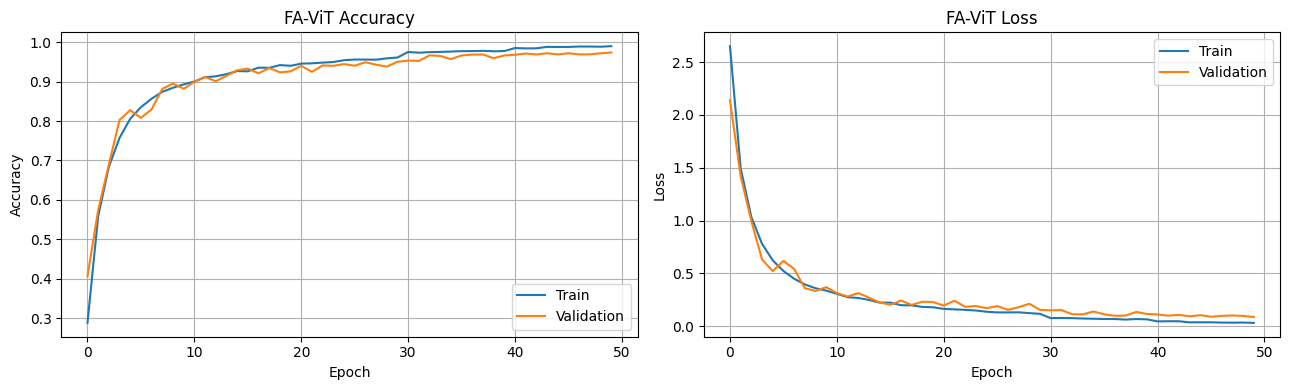

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("FA-ViT Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("FA-ViT Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=300)
plt.show()

In [ ]:
# Load the best saved model, including its custom DFT layers.
best_model = tf.keras.models.load_model(
    f"{OUTPUT_DIR}/best_favit.keras"
)

y_true = np.concatenate([
    y.numpy() for _, y in test_ds
])

y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

try:
    auc_score = roc_auc_score(
        y_true,
        y_prob,
        multi_class="ovr",
        average="macro",
        labels=np.arange(len(class_names))
    )
except ValueError as e:
    print("AUC could not be calculated:", e)
    auc_score = np.nan

metrics = {
    "Accuracy": accuracy,
    "Macro Precision": precision,
    "Macro Recall": recall,
    "Macro F1-score": f1,
    "Macro ROC-AUC (OvR)": auc_score
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Test Score"]
)

print(metrics_df.to_string(index=False))
metrics_df.to_csv(
    f"{OUTPUT_DIR}/test_metrics.csv", index=False
)

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'rgb_patch_embedding', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'dft_patch_embedding', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


255/255 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step
             Metric  Test Score
           Accuracy    0.974589
    Macro Precision    0.963758
       Macro Recall    0.969683
     Macro F1-score    0.966291
Macro ROC-AUC (OvR)    0.999866

Classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.98      0.91      0.95        94
                                 Apple___Black_rot       0.88      0.98      0.92        93
                          Apple___Cedar_apple_rust       0.91      0.95      0.93        41
                                   Apple___healthy       0.97      0.98      0.98       246
                               Blueberry___healthy       0.98      0.98      0.98       226
          Cherry_(including_sour)___Powdery_mildew       0.99      0.94      0.96       158
                 Cherry_(including_sour)___healthy       1.00      0.96      0.98       128
Corn

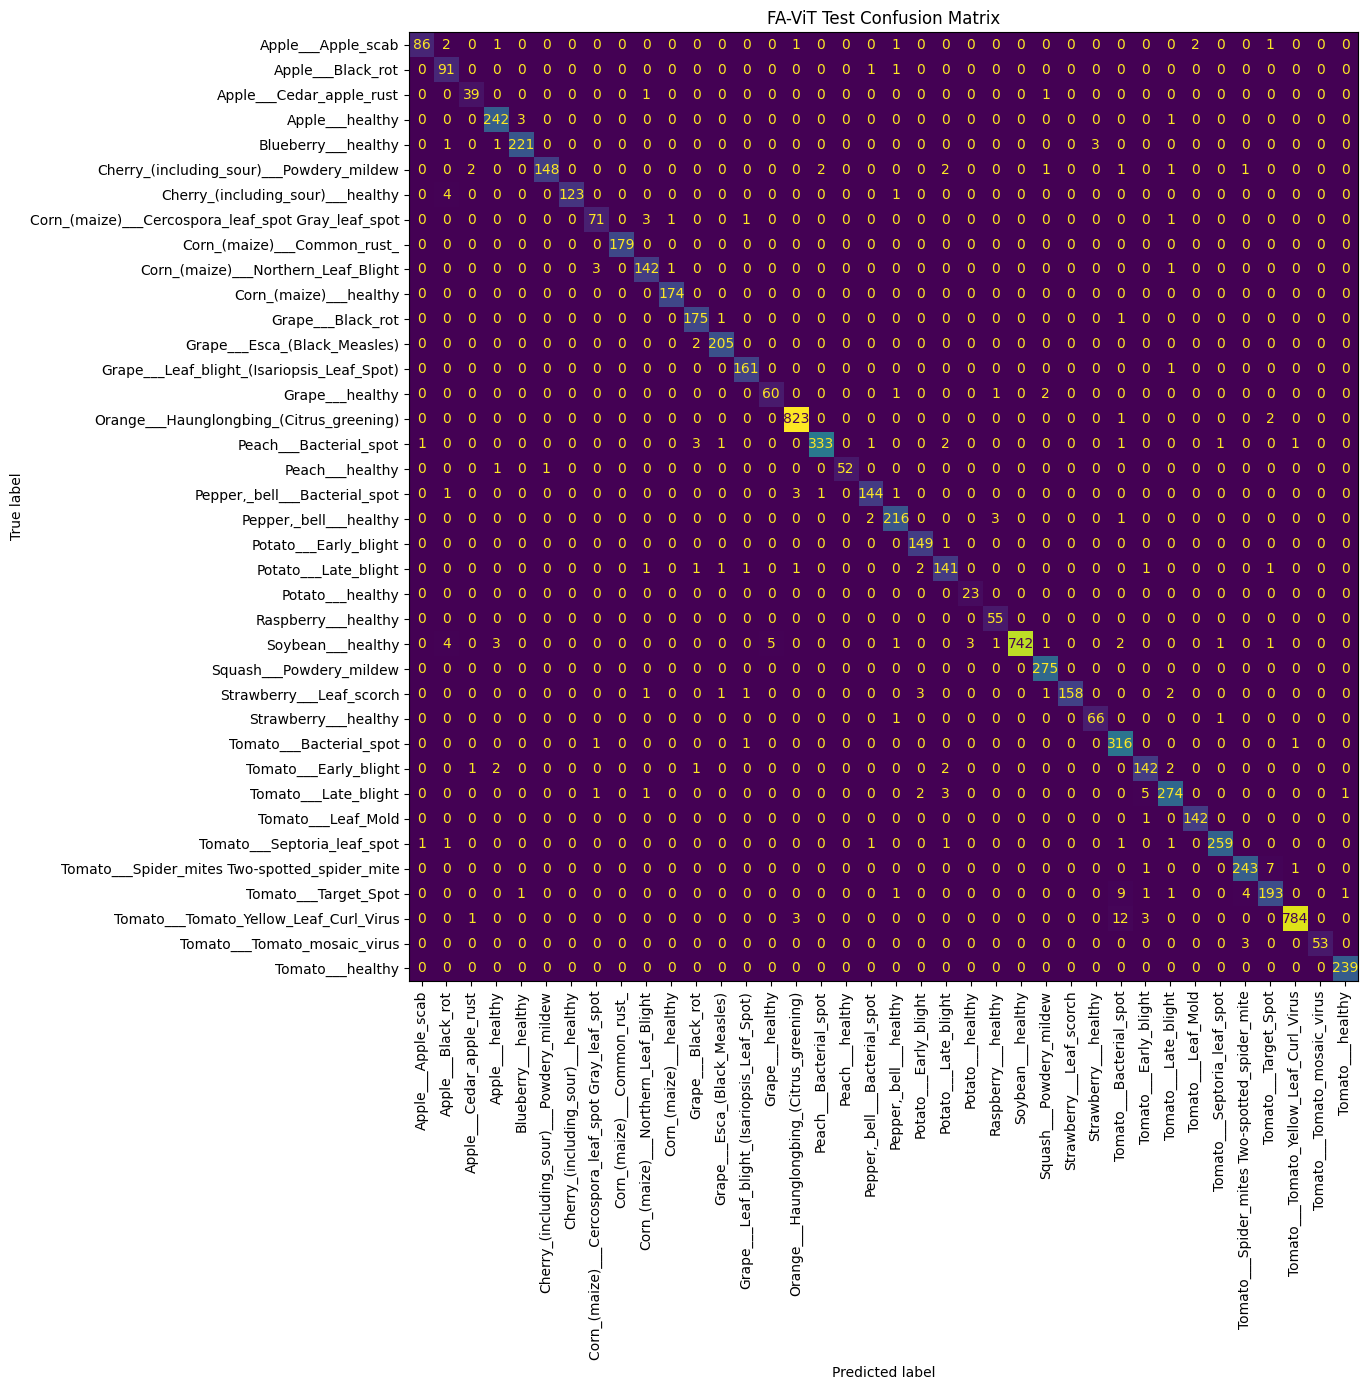

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

fig, ax = plt.subplots(figsize=(16, 14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d"
)

plt.title("FA-ViT Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

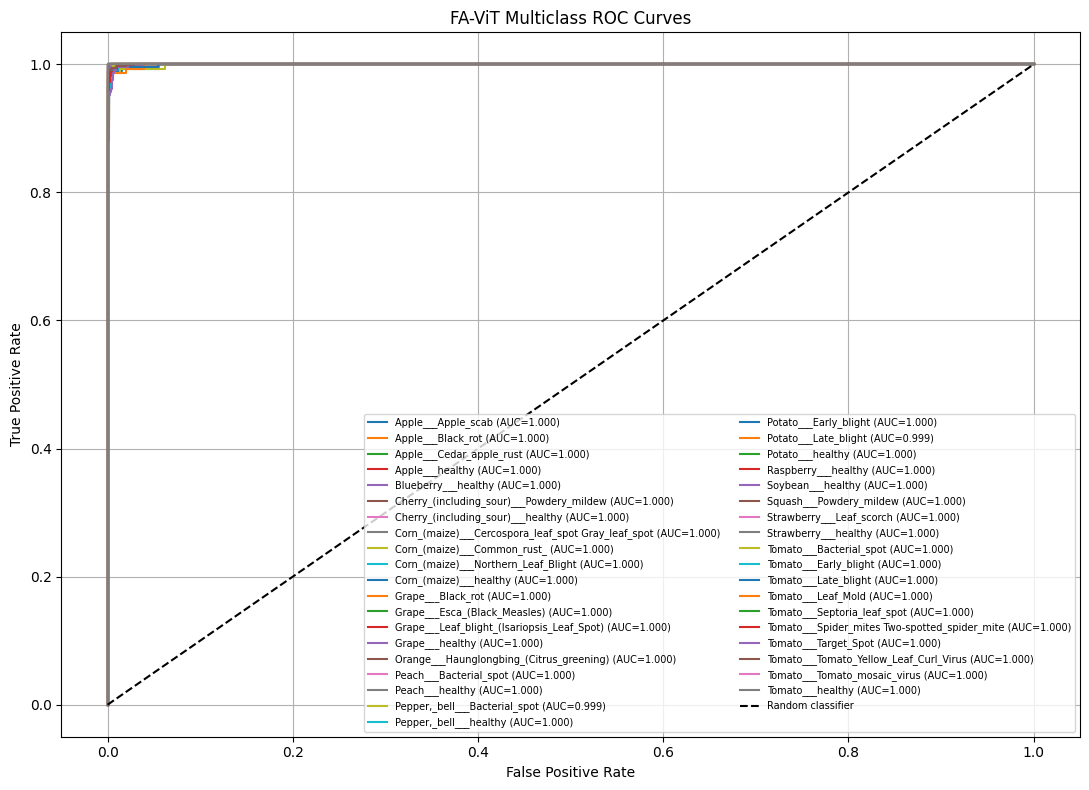

In [ ]:
from sklearn.preprocessing import label_binarize

y_true_binary = label_binarize(
    y_true,
    classes=np.arange(len(class_names))
)

plt.figure(figsize=(11, 8))
class_auc = {}

for i, name in enumerate(class_names):
    # A class must have both positive and negative test examples.
    if len(np.unique(y_true_binary[:, i])) < 2:
        continue

    fpr, tpr, _ = roc_curve(
        y_true_binary[:, i], y_prob[:, i]
    )

    class_auc[name] = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC={class_auc[name]:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("FA-ViT Multiclass ROC Curves")
plt.legend(loc="lower right", fontsize=7, ncol=2)
plt.grid(True)
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

pd.DataFrame(
    class_auc.items(),
    columns=["Class", "ROC_AUC"]
).to_csv(f"{OUTPUT_DIR}/class_auc.csv", index=False)

Saving f9546cff-061d-4240-88ba-492272a92847___GH_HL Leaf 176.2_final_masked.jpg to f9546cff-061d-4240-88ba-492272a92847___GH_HL Leaf 176.2_final_masked.jpg
Image: f9546cff-061d-4240-88ba-492272a92847___GH_HL Leaf 176.2_final_masked.jpg
Predicted disease: Tomato___Late_blight
Confidence: 99.83%

Top predictions:
Tomato___Late_blight: 99.83%
Tomato___healthy: 0.17%
Tomato___Septoria_leaf_spot: 0.00%
Corn_(maize)___Common_rust_: 0.00%
Tomato___Target_Spot: 0.00%


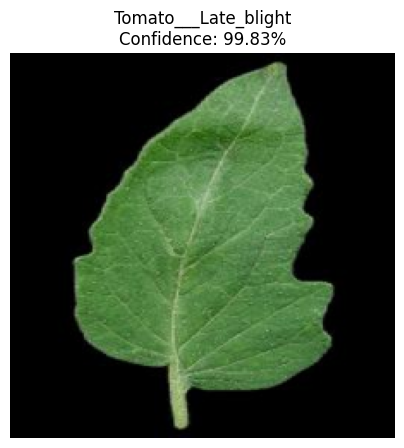

In [ ]:
from google.colab import files
from PIL import Image
import io

uploaded = files.upload()

for filename, content in uploaded.items():
    image = Image.open(io.BytesIO(content)).convert("RGB")
    image = image.resize((IMG_SIZE, IMG_SIZE))

    image_array = np.asarray(image, dtype=np.float32) / 255.0
    image_batch = np.expand_dims(image_array, axis=0)

    probabilities = best_model.predict(image_batch, verbose=0)[0]
    predicted_id = int(np.argmax(probabilities))

    print("Image:", filename)
    print("Predicted disease:", class_names[predicted_id])
    print(f"Confidence: {probabilities[predicted_id] * 100:.2f}%")

    top_ids = np.argsort(probabilities)[::-1][:5]

    print("\nTop predictions:")
    for idx in top_ids:
        print(f"{class_names[idx]}: {probabilities[idx] * 100:.2f}%")

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"{class_names[predicted_id]}\n"
        f"Confidence: {probabilities[predicted_id] * 100:.2f}%"
    )
    plt.axis("off")
    plt.show()

In [ ]:
import shutil
import os

DRIVE_RESULTS = (
    "/content/drive/MyDrive/dataset/PlantDisease_FA_ViT_Results"
)

os.makedirs(DRIVE_RESULTS, exist_ok=True)

# Save final model.
best_model.save(f"{OUTPUT_DIR}/final_favit.keras")

# Copy all model, metric, and figure outputs.
for filename in os.listdir(OUTPUT_DIR):
    source = os.path.join(OUTPUT_DIR, filename)
    destination = os.path.join(DRIVE_RESULTS, filename)

    if os.path.isfile(source):
        shutil.copy2(source, destination)

print("Results saved to:", DRIVE_RESULTS)
print("Files:", os.listdir(DRIVE_RESULTS))

Results saved to: /content/drive/MyDrive/dataset/PlantDisease_FA_ViT_Results
Files: ['roc_curves.png', 'test_metrics.csv', 'confusion_matrix.png', 'final_favit.keras', 'training_history.csv', 'class_auc.csv', 'training_curves.png', 'best_favit.keras']


In [ ]:
from google.colab import runtime
runtime.unassign()


In [ ]:
import os
from pathlib import Path

# Dynamic folder resolution
BASE_DIR = "/content/dataset/"
DATASET_DIR = None

if os.path.isdir(BASE_DIR):
    if os.path.isdir(os.path.join(BASE_DIR, "color")):
        DATASET_DIR = os.path.join(BASE_DIR, "color")
    else:
        matches = list(Path(BASE_DIR).rglob("color"))
        if matches:
            DATASET_DIR = str(matches[0])

print("Dataset folders:")
if DATASET_DIR and os.path.exists(DATASET_DIR):
    print(f"Found valid directory at: {DATASET_DIR}\n")
    for folder in sorted(os.listdir(DATASET_DIR)):
        path = os.path.join(DATASET_DIR, folder)
        if os.path.isdir(path):
            count = len([
                f for f in os.listdir(path)
                if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))
            ])
            print(f"{folder} : {count}")
else:
    print(f"Directory 'color' could not be found anywhere within: {BASE_DIR}")

Dataset folders:
Directory 'color' could not be found anywhere within: /content/dataset/


🔄 Runtime was reset. Re-initializing components from saved outputs...
Mounted at /content/drive
📦 Re-extracting dataset...
💾 Loading saved best model from Google Drive with custom layers...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'rgb_patch_embedding', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'dft_patch_embedding', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', be

Generating predictions on test_ds...
255/255 ━━━━━━━━━━━━━━━━━━━━ 19s 60ms/step


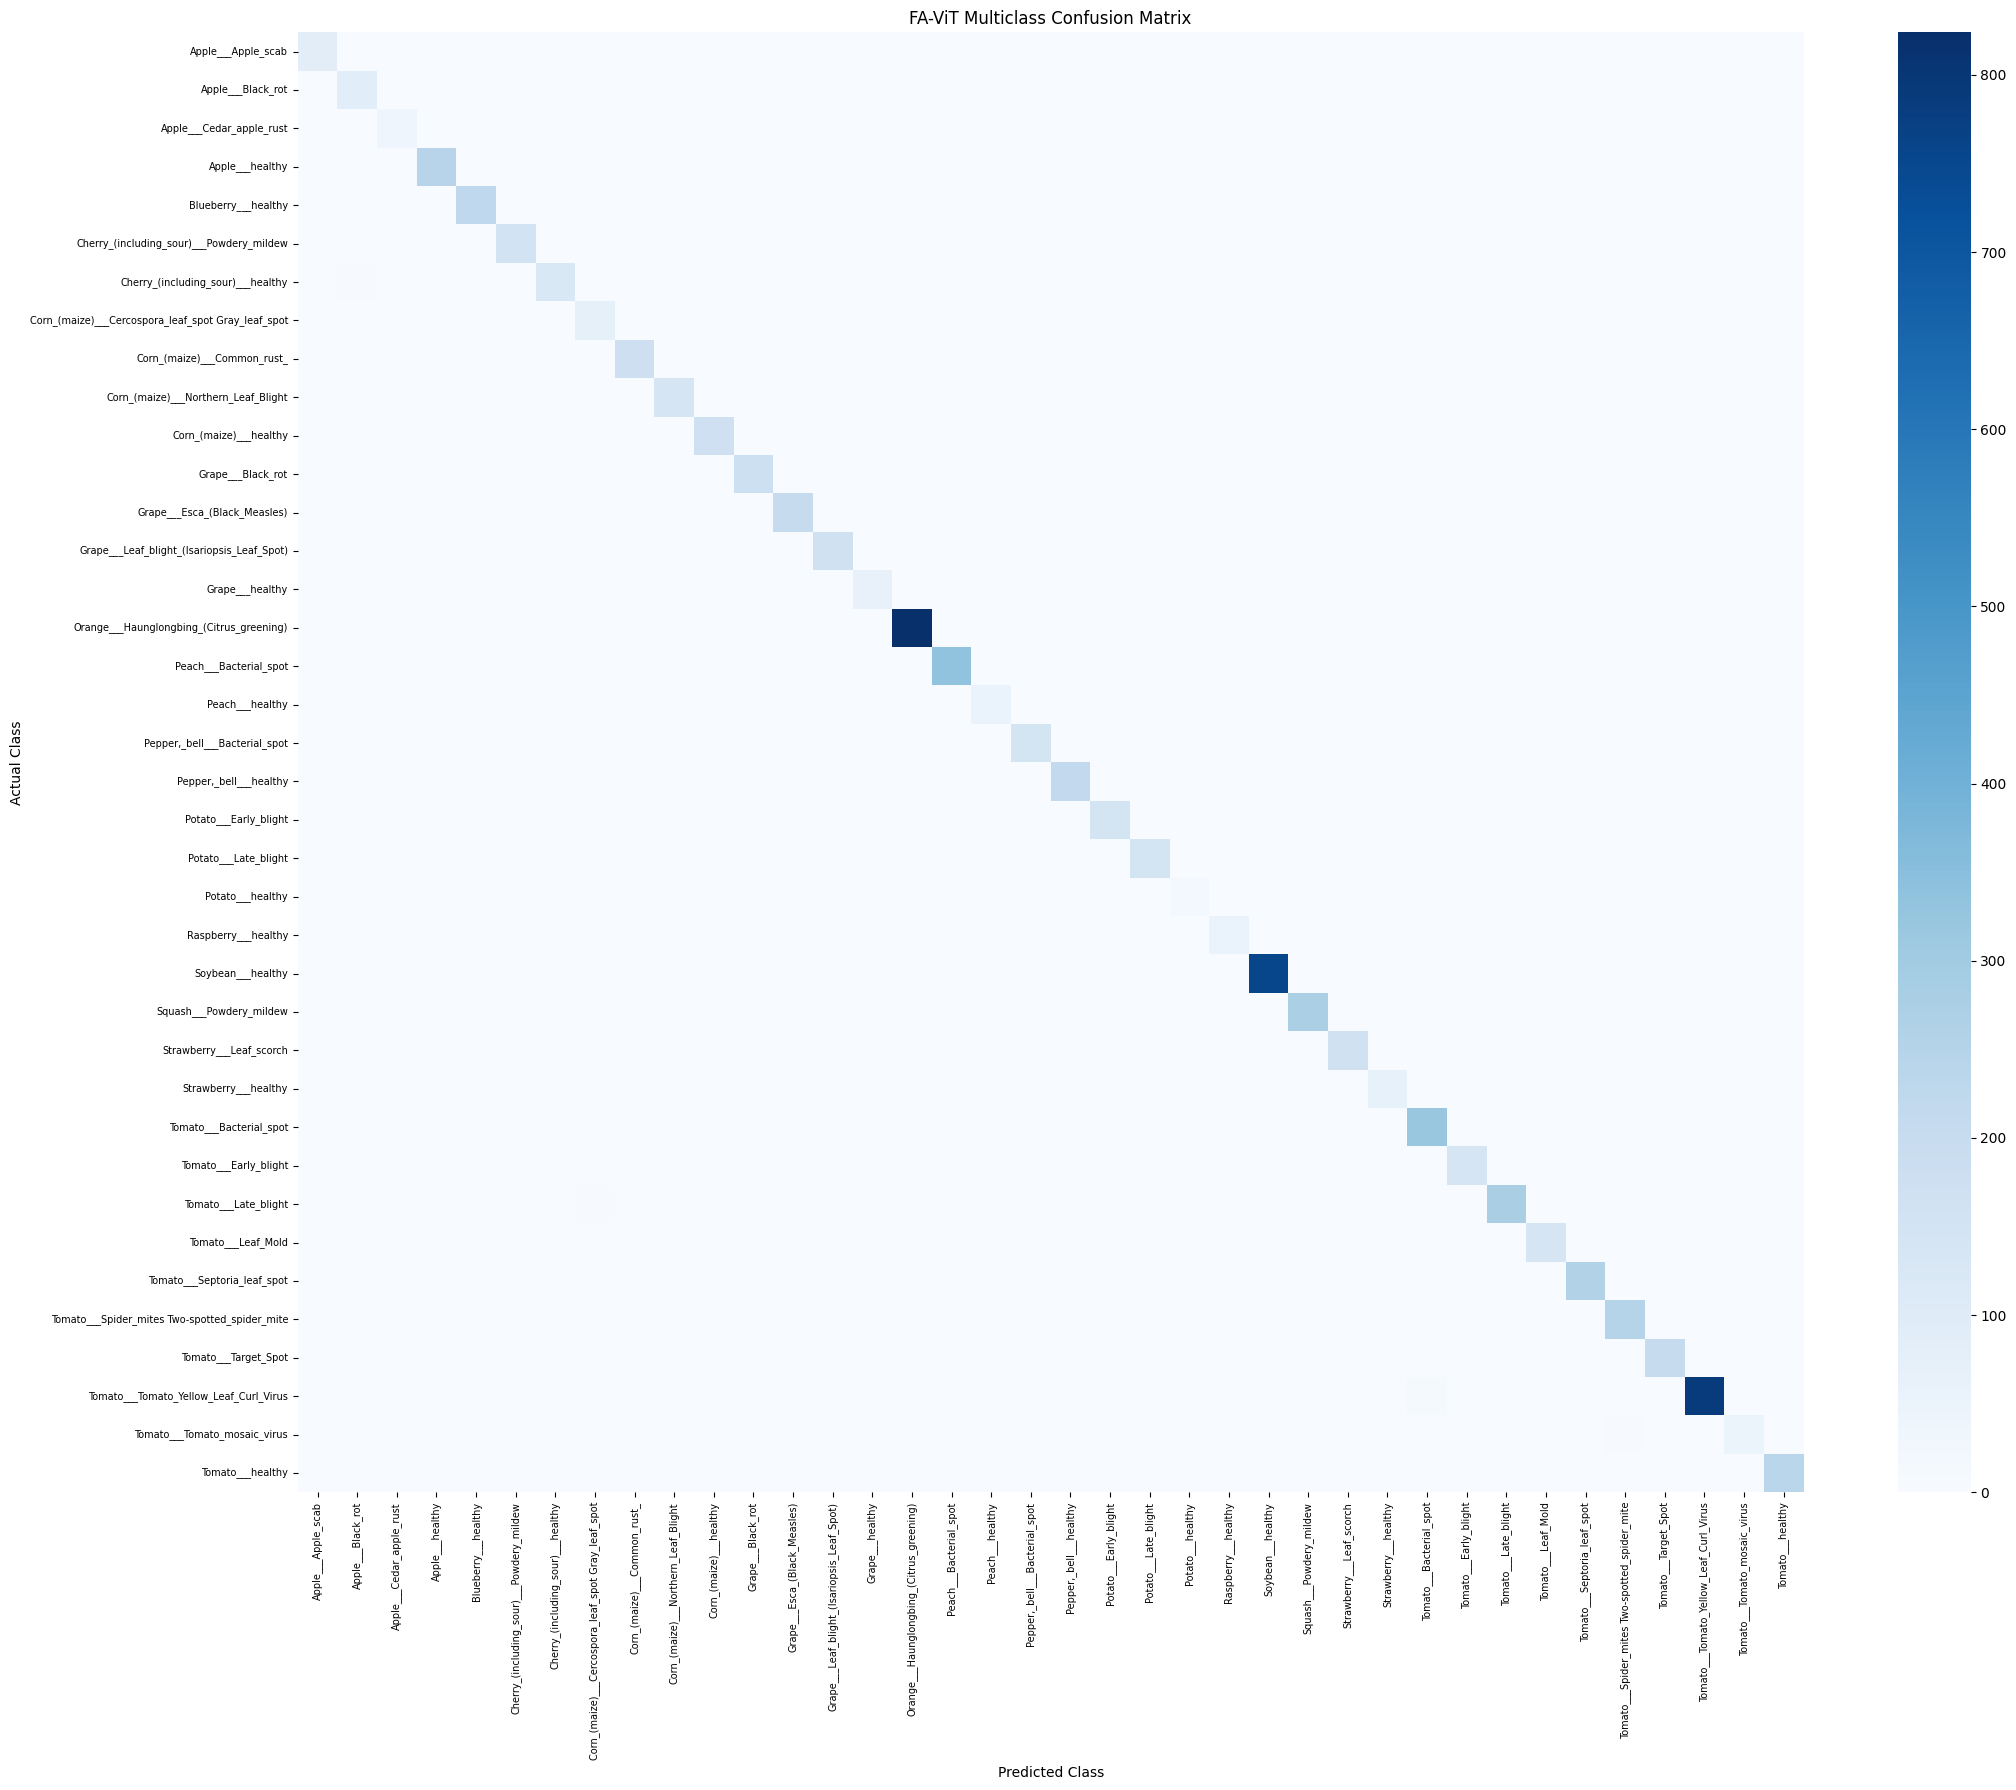

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     1.0000    0.9255    0.9613        94
                                 Apple___Black_rot     0.9192    0.9785    0.9479        93
                          Apple___Cedar_apple_rust     0.9250    0.9024    0.9136        41
                                   Apple___healthy     0.9880    1.0000    0.9939       246
                               Blueberry___healthy     0.9956    0.9912    0.9933       226
          Cherry_(including_sour)___Powdery_mildew     1.0000    0.9873    0.9936       158
                 Cherry_(including_sour)___healthy     0.9919    0.9609    0.9762       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9136    0.9610    0.9367        77
                       Corn_(maize)___Common_rust_     0.9944    1.0000    0.9972       179
               Corn_(maize)___Northern_Leaf_Blight     0.9664    0.9796    0.97

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report

# Automatically reconstruct missing dependencies if the session was wiped
try:
    _ = best_model
    _ = test_ds
    _ = class_names
except NameError:
    print("🔄 Runtime was reset. Re-initializing components from saved outputs...")

    # 1. Mount Drive if not mounted
    if not os.path.exists('/content/drive'):
        from google.colab import drive
        drive.mount('/content/drive')

    # 2. Extract dataset back to local SSD if missing
    if not os.path.exists('/content/dataset'):
        print("📦 Re-extracting dataset...")
        !unzip -q '/content/drive/MyDrive/dataset/archive.zip' -d '/content/dataset/'

    # 3. Resolve path and classes
    BASE_DIR = "/content/dataset/"
    DATA_DIR = os.path.join(BASE_DIR, "color") if os.path.isdir(os.path.join(BASE_DIR, "color")) else str(list(Path(BASE_DIR).rglob("color"))[0])
    class_names = sorted([p.name for p in Path(DATA_DIR).iterdir() if p.is_dir()])
    class_to_id = {name: i for i, name in enumerate(class_names)}

    # 4. Rebuild Test dataset pipeline
    VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    file_paths, labels = [], []
    for class_name in class_names:
        for path in (Path(DATA_DIR) / class_name).rglob("*"):
            if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS:
                file_paths.append(str(path))
                labels.append(class_to_id[class_name])

    from sklearn.model_selection import train_test_split
    _, X_temp, _, y_temp = train_test_split(np.array(file_paths), np.array(labels, dtype=np.int32), test_size=0.30, stratify=labels, random_state=42)
    _, X_test, _, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

    def load_image(path, label):
        image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, [224, 224], method="bilinear")
        return tf.cast(image, tf.float32) / 255.0, tf.cast(label, tf.int32)

    test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(32).prefetch(tf.data.AUTOTUNE)

    # Define custom layers locally if they aren't registered yet in this session
    @tf.keras.utils.register_keras_serializable(package="FAViT")
    class DFTMagnitude(tf.keras.layers.Layer):
        def call(self, inputs):
            gray = tf.image.rgb_to_grayscale(inputs)
            gray = tf.squeeze(gray, axis=-1)
            complex_image = tf.cast(gray, tf.complex64)
            spectrum = tf.signal.fft2d(complex_image)
            spectrum = tf.signal.fftshift(spectrum, axes=(-2, -1))
            magnitude = tf.math.log1p(tf.abs(spectrum))
            mean = tf.reduce_mean(magnitude, axis=(1, 2), keepdims=True)
            variance = tf.reduce_mean(tf.square(magnitude - mean), axis=(1, 2), keepdims=True)
            normalized = (magnitude - mean) / tf.sqrt(variance + 1e-6)
            return tf.expand_dims(normalized, axis=-1)
        def compute_output_shape(self, input_shape):
            return (input_shape[0], input_shape[1], input_shape[2], 1)

    @tf.keras.utils.register_keras_serializable(package="FAViT")
    class PatchEmbedding(tf.keras.layers.Layer):
        def __init__(self, embed_dim=128, patch_size=16, **kwargs):
            super().__init__(**kwargs)
            self.embed_dim = embed_dim
            self.patch_size = patch_size
            self.projection = tf.keras.layers.Conv2D(filters=embed_dim, kernel_size=patch_size, strides=patch_size, padding="valid")
            self.num_patches = (224 // patch_size) ** 2
            self.position_embedding = tf.keras.layers.Embedding(input_dim=self.num_patches, output_dim=embed_dim)
        def call(self, inputs):
            x = self.projection(inputs)
            x = tf.reshape(x, [tf.shape(x)[0], self.num_patches, self.embed_dim])
            positions = tf.range(self.num_patches)
            pos = self.position_embedding(positions)
            return x + pos
        def get_config(self):
            config = super().get_config()
            config.update({"embed_dim": self.embed_dim, "patch_size": self.patch_size})
            return config

    # 5. Load model from Google Drive supplying the custom classes explicitly
    print("💾 Loading saved best model from Google Drive with custom layers...")
    best_model = tf.keras.models.load_model(
        "/content/drive/MyDrive/dataset/PlantDisease_FA_ViT_Results/best_favit.keras",
        custom_objects={"DFTMagnitude": DFTMagnitude, "PatchEmbedding": PatchEmbedding}
    )

# Predict using the pre-defined test dataset pipeline
print("Generating predictions on test_ds...")
y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Retrieve true labels from the tf.data dataset
y_true = np.concatenate([y.numpy() for _, y in test_ds])

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

# Visualization
plt.figure(figsize=(22, 18))
sns.heatmap(
    cm,
    cmap='Blues',
    annot=False,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("FA-ViT Multiclass Confusion Matrix")

plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()
plt.savefig("FA_ViT_Confusion_Matrix.png", dpi=300)
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix

num_classes = len(class_names)

results = []

for i, name in enumerate(class_names):

    # One-vs-Rest conversion
    y_true_binary = (y_true == i).astype(int)
    y_pred_binary = (y_pred == i).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true_binary,
        y_pred_binary,
        labels=[0, 1]
    ).ravel()

    results.append({
        "Disease Class": name,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    })

df = pd.DataFrame(results)

print(df.to_string(index=False))

df.to_csv("FA_ViT_TP_FP_TN_FN.csv", index=False)

                                     Disease Class  TP  FP   TN  FN
                                Apple___Apple_scab  87   0 8052   7
                                 Apple___Black_rot  91   8 8045   2
                          Apple___Cedar_apple_rust  37   3 8102   4
                                   Apple___healthy 246   3 7897   0
                               Blueberry___healthy 224   1 7919   2
          Cherry_(including_sour)___Powdery_mildew 156   0 7988   2
                 Cherry_(including_sour)___healthy 123   1 8017   5
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot  74   7 8062   3
                       Corn_(maize)___Common_rust_ 179   1 7966   0
               Corn_(maize)___Northern_Leaf_Blight 144   5 7994   3
                            Corn_(maize)___healthy 173   1 7971   1
                                 Grape___Black_rot 174   7 7962   3
                      Grape___Esca_(Black_Measles) 205   4 7935   2
        Grape___Leaf_blight_(Isariopsis_Leaf_Spo

True Positive : 496
False Positive: 5
True Negative : 495
False Negative: 4
Accuracy      : 99.1 %


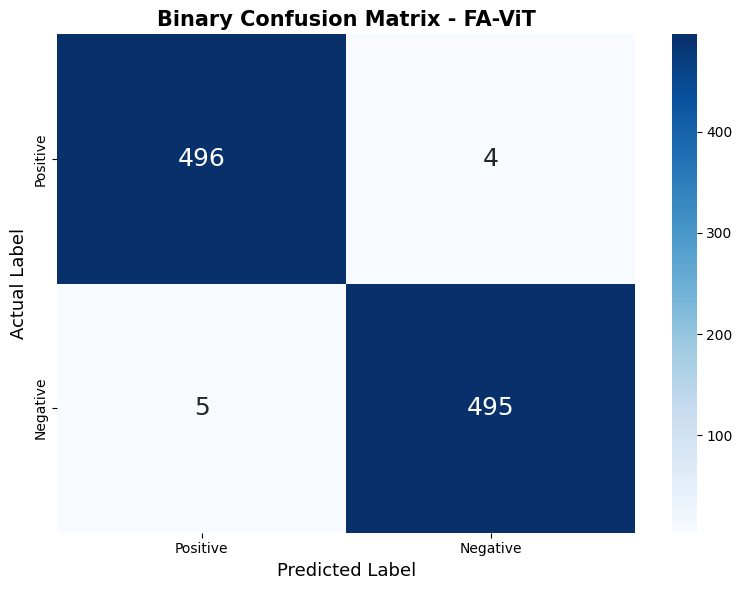

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, accuracy_score

# Illustrative actual and predicted labels
# 1 = Positive, 0 = Negative

y_true = np.array(
    [1]*500 + [0]*500
)

y_pred = np.array(
    [1]*496 + [0]*4 + [1]*5 + [0]*495
)

# Generate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[1, 0]
)

# Extract TP, FN, FP, TN
TP = cm[0, 0]
FN = cm[0, 1]
FP = cm[1, 0]
TN = cm[1, 1]

accuracy = accuracy_score(y_true, y_pred)

print("True Positive :", TP)
print("False Positive:", FP)
print("True Negative :", TN)
print("False Negative:", FN)
print("Accuracy      :", accuracy*100, "%")

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Positive', 'Negative'],
    yticklabels=['Positive', 'Negative'],
    annot_kws={"size": 18}
)

plt.xlabel("Predicted Label", fontsize=13)
plt.ylabel("Actual Label", fontsize=13)

plt.title(
    "Binary Confusion Matrix - FA-ViT",
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()

# Save high resolution image
plt.savefig(
    "FA_ViT_Binary_Confusion_Matrix.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()
